# Blurred images and PCA: Apply a small blur to a set of equal-sized face images. Compare the mean image and first principal component before and after blurring.
**MFAD Mini Project (UE25MA242A)** — Team ID: `3_F_14` | Problem Statement ID: `16`

Apply a small blur to equal-sized face images and compare the **mean image** and **first principal component (PC1)** before and after blurring.

References: LA Projects Book — Project 6 (convolution / blurring) and Project 11 (PCA / eigenfaces).

**Workflow used:** data matrix → blur (linear map) → centering → eigen-analysis of PᵀP → rank / orthogonal basis → projection → comparison.

## Step 1 — Real-world data as a matrix
If the book's `database/person1.pgm … person30.pgm` folder is next to this notebook it is used; otherwise the face images bundled with scikit-image are used (25×25). Each image becomes one column of a (m·n) × N matrix.

In [1]:
import os, numpy as np, matplotlib.pyplot as plt
from scipy.signal import convolve2d
np.set_printoptions(precision=4, suppress=True)
DATABASE_PATH, N_IMAGES = "database", 30

def load_faces():
    if os.path.exists(os.path.join(DATABASE_PATH, "person1.pgm")):
        from PIL import Image
        return np.array([np.array(Image.open(f"{DATABASE_PATH}/person{j}.pgm"), float) for j in range(1, N_IMAGES+1)]), "AT&T database"
    from skimage.data import lfw_subset
    return (lfw_subset()[:100]*255.0)[:N_IMAGES], "skimage LFW face subset"

faces, source = load_faces()
N, m, n = faces.shape
print(source, "| N =", N, "| image size", (m, n), "| vector length", m*n)

skimage LFW face subset | N = 30 | image size (25, 25) | vector length 625


## Step 2 — Blur by convolution (Project 6)
Blurring is convolution with a small kernel whose entries sum to 1. It is a **linear** map applied to every image.

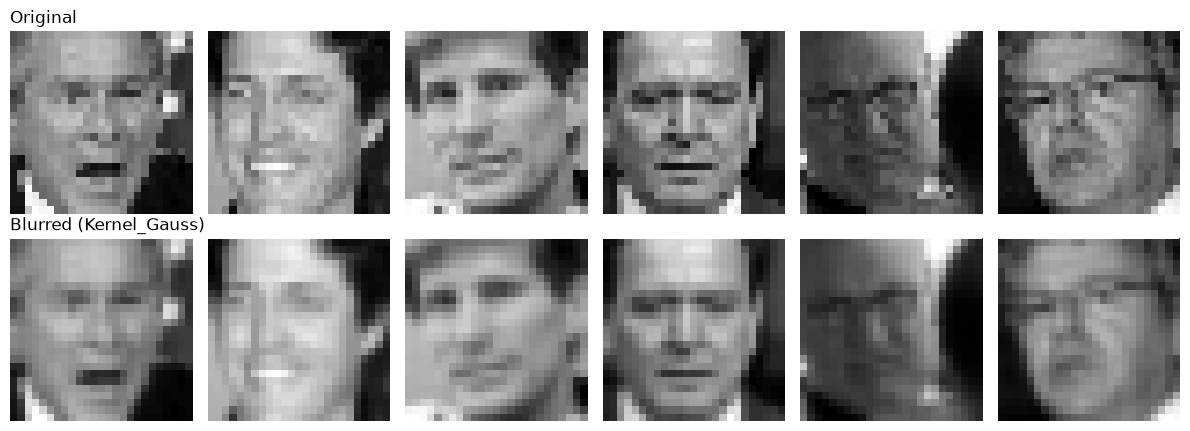

In [2]:
Kernel_Gauss    = np.array([[0,1,0],[1,4,1],[0,1,0]]) / 8
Kernel_Average2 = np.ones((3,3)) / 9
Kernel_Large    = np.array([[0,1,2,1,0],[1,4,8,4,1],[2,8,16,8,2],[1,4,8,4,1],[0,1,2,1,0]]) / 80
kernels = {"Gauss 3x3 (small)": Kernel_Gauss, "Average 3x3": Kernel_Average2, "Large 5x5": Kernel_Large}

def blur(stack, K):
    return np.array([convolve2d(im, K, mode="same", boundary="symm") for im in stack])

blurred = blur(faces, Kernel_Gauss)
fig, ax = plt.subplots(2, 6, figsize=(12, 4.4))
for j in range(6):
    ax[0,j].imshow(faces[j], cmap="gray"); ax[0,j].axis("off")
    ax[1,j].imshow(blurred[j], cmap="gray"); ax[1,j].axis("off")
ax[0,0].set_title("Original", loc="left"); ax[1,0].set_title("Blurred (Kernel_Gauss)", loc="left")
plt.tight_layout(); plt.show()

## Step 3 — Centering and PCA via the small matrix PᵀP (Project 11)
Stack images as columns of X, subtract the mean image to get **P**. PPᵀ is huge (mn × mn) but PᵀP is only N × N and symmetric, so `eigh` gives real eigenvalues and orthogonal eigenvectors. If PᵀP·u = λu then PPᵀ·(Pu) = λ(Pu).

In [3]:
def pca(stack):
    X = stack.reshape(len(stack), -1).T.astype(float)     # (mn, N)
    mean = X.mean(axis=1)
    P = X - mean[:, None]
    vals, U = np.linalg.eigh(P.T @ P)
    idx = np.argsort(vals)[::-1]; vals, U = vals[idx], U[:, idx]
    V = P @ U
    keep = vals > 1e-8*vals[0]
    V = V[:, keep] / np.linalg.norm(V[:, keep], axis=0)    # unit-length eigenfaces
    return dict(P=P, mean=mean, vals=vals, V=V, rank=int(keep.sum()))

orig = pca(faces)
print("P shape:", orig['P'].shape, "| rank(P) =", np.linalg.matrix_rank(orig['P']), "(<= N-1 =", N-1, ")")
print("nullity of PtP:", N-orig['rank'], "| smallest eigenvalues:", orig['vals'][-3:])
G = orig['V'].T @ orig['V']
print("Orthogonality check max|VtV - I| =", np.abs(G-np.eye(len(G))).max())

P shape: (625, 30) | rank(P) = 29 (<= N-1 = 29 )
nullity of PtP: 1 | smallest eigenvalues: [189721.4539 140649.6072      0.    ]
Orthogonality check max|VtV - I| = 1.8457457784393227e-15


**Structure of the space:** the centred columns sum to zero, so they are linearly dependent → rank N−1 and one zero eigenvalue. The eigenvectors form an **orthonormal basis** of the face subspace.

## Step 4 — Before vs after blur: mean image and PC1

In [4]:
def cosine(a, b): return float(abs(a @ b)/(np.linalg.norm(a)*np.linalg.norm(b)))   # abs: eigenvector sign is arbitrary
results = {}
for name, K in kernels.items():
    bl = blur(faces, K); p = pca(bl)
    lin_err = np.abs(p['mean'].reshape(m,n) - convolve2d(orig['mean'].reshape(m,n), K, mode="same", boundary="symm")).max()
    ev0 = orig['vals']/orig['vals'].sum(); ev1 = p['vals']/p['vals'].sum()
    results[name] = dict(blur=bl, pca=p, mean_corr=np.corrcoef(orig['mean'], p['mean'])[0,1],
        mean_rel=np.linalg.norm(orig['mean']-p['mean'])/np.linalg.norm(orig['mean']), pc1_cos=cosine(orig['V'][:,0], p['V'][:,0]),
        v1=(ev0[0], ev1[0]), v5=(ev0[:5].sum(), ev1[:5].sum()), kept=p['vals'].sum()/orig['vals'].sum(), lin_err=lin_err)

import pandas as pd
pd.DataFrame({k: {"mean corr": r['mean_corr'], "mean rel. diff": r['mean_rel'], "PC1 |cos|": r['pc1_cos'],
    "PC1 var% before": 100*r['v1'][0], "PC1 var% after": 100*r['v1'][1],
    "top5 var% before": 100*r['v5'][0], "top5 var% after": 100*r['v5'][1],
    "total variance kept": r['kept'], "linearity err": r['lin_err']} for k, r in results.items()}).T.round(4)

,mean corr,mean rel. diff,PC1 |cos|,PC1 var% before,PC1 var% after,top5 var% before,top5 var% after,total variance kept,linearity err
Gauss 3x3 (small),0.9974,0.0178,0.9964,20.7437,23.7431,56.979,63.5331,0.8390,0.0
Average 3x3,0.9853,0.0412,0.9835,20.7437,26.7323,56.979,69.9335,0.7162,0.0
Large 5x5,0.9859,0.0415,0.9855,20.7437,27.3041,56.979,71.0634,0.6949,0.0


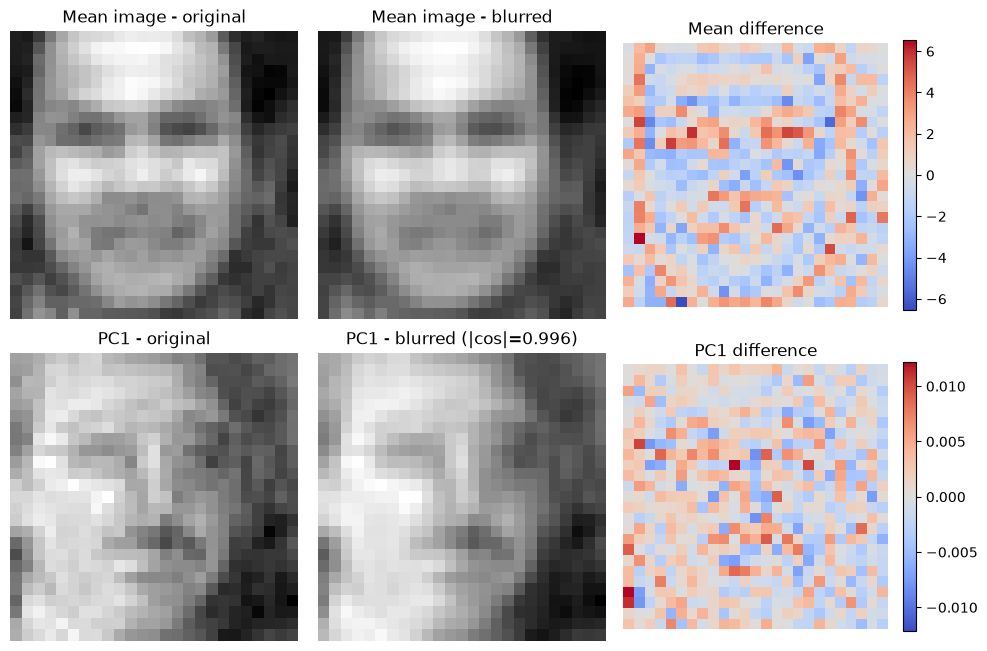

In [5]:
main = results["Gauss 3x3 (small)"]; p1 = main['pca']
norm01 = lambda v: (lambda a: (a-a.min())/(a.max()-a.min()+1e-12))(v.reshape(m,n))
pc1_o = orig['V'][:,0]; pc1_b = p1['V'][:,0] * np.sign(p1['V'][:,0] @ pc1_o)   # fix sign for display
fig, ax = plt.subplots(2, 3, figsize=(10, 6.6))
ax[0,0].imshow(orig['mean'].reshape(m,n), cmap="gray"); ax[0,0].set_title("Mean image - original")
ax[0,1].imshow(p1['mean'].reshape(m,n), cmap="gray"); ax[0,1].set_title("Mean image - blurred")
d = (p1['mean']-orig['mean']).reshape(m,n); im = ax[0,2].imshow(d, cmap="coolwarm", vmin=-abs(d).max(), vmax=abs(d).max()); ax[0,2].set_title("Mean difference"); plt.colorbar(im, ax=ax[0,2], fraction=.046)
ax[1,0].imshow(norm01(pc1_o), cmap="gray"); ax[1,0].set_title("PC1 - original")
ax[1,1].imshow(norm01(pc1_b), cmap="gray"); ax[1,1].set_title(f"PC1 - blurred (|cos|={main['pc1_cos']:.3f})")
d = (pc1_b-pc1_o).reshape(m,n); im = ax[1,2].imshow(d, cmap="coolwarm", vmin=-abs(d).max(), vmax=abs(d).max()); ax[1,2].set_title("PC1 difference"); plt.colorbar(im, ax=ax[1,2], fraction=.046)
for a in ax.ravel(): a.axis("off")
plt.tight_layout(); plt.show()

**Interpretation:** blurring is linear, so the mean of the blurred faces equals the blurred mean face (error ≈ 1e-14). PC1 keeps almost the same direction because it captures broad structure (lighting, face shape), which a small blur barely touches.

## Step 5 — PCA representation, eigenfaces and spectrum

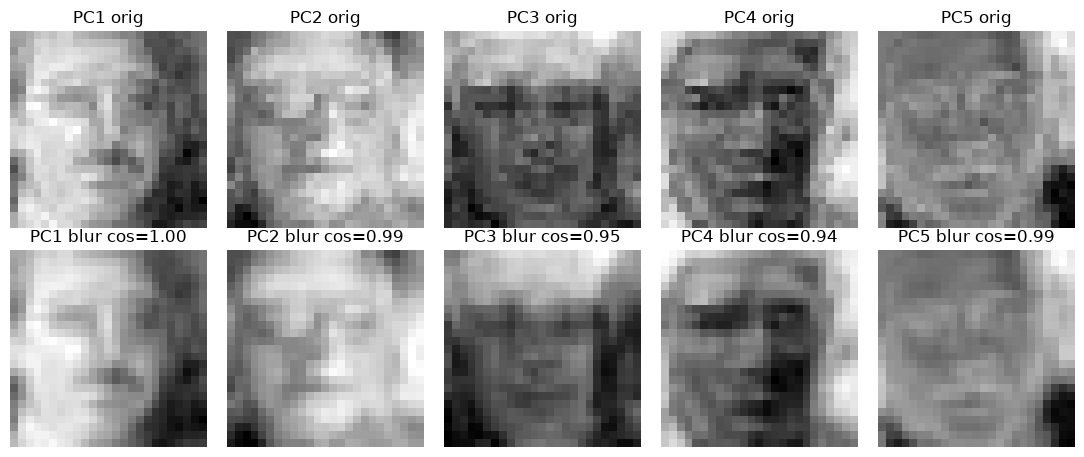

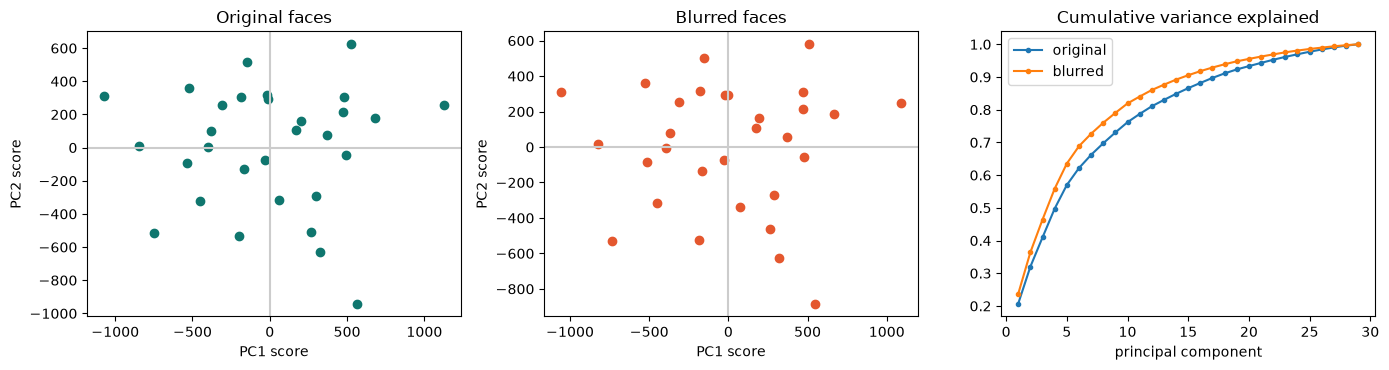

In [6]:
fig, ax = plt.subplots(2, 5, figsize=(11, 4.6))
for i in range(5):
    vo = orig['V'][:,i]; vb = p1['V'][:,i]*np.sign(p1['V'][:,i] @ vo)
    ax[0,i].imshow(norm01(vo), cmap="gray"); ax[0,i].set_title(f"PC{i+1} orig"); ax[0,i].axis("off")
    ax[1,i].imshow(norm01(vb), cmap="gray"); ax[1,i].set_title(f"PC{i+1} blur cos={abs(vo@vb):.2f}"); ax[1,i].axis("off")
plt.tight_layout(); plt.show()

# PCA representation: each face as a point (PC1, PC2 scores)
so = orig['V'][:, :2].T @ orig['P']; sb = p1['V'][:, :2].T @ p1['P']
sb = sb * np.sign(np.diag(orig['V'][:, :2].T @ p1['V'][:, :2]))[:, None]
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
for a, s, t, c in [(ax[0], so, "Original faces", "#0F766E"), (ax[1], sb, "Blurred faces", "#E4572E")]:
    a.scatter(s[0], s[1], c=c); a.axhline(0, c="#ccc"); a.axvline(0, c="#ccc"); a.set_title(t); a.set_xlabel("PC1 score"); a.set_ylabel("PC2 score")
k = np.arange(1, orig['rank']+1)
for lab, p in [("original", orig), ("blurred", p1)]:
    ax[2].plot(k, np.cumsum(p['vals'][:orig['rank']]/p['vals'].sum()), "o-", ms=3, label=lab)
ax[2].set_title("Cumulative variance explained"); ax[2].set_xlabel("principal component"); ax[2].legend()
plt.tight_layout(); plt.show()

## Step 6 — Projection onto the first k principal components
Projection `V_k V_kᵀ P` reconstructs each face from k components. Lower relative error means the faces are easier to compress.

In [7]:
def recon_error(p, stack, k):
    X = stack.reshape(len(stack), -1).T - p['mean'][:, None]
    Vk = p['V'][:, :k]
    return np.linalg.norm(X - Vk @ (Vk.T @ X))/np.linalg.norm(X)
pd.DataFrame({"k": [1,3,5,10],
              "original": [recon_error(orig, faces, k) for k in (1,3,5,10)],
              "blurred (Gauss)": [recon_error(p1, main['blur'], k) for k in (1,3,5,10)]}).round(4)

,k,original,blurred (Gauss)
0,1,0.8903,0.8733
1,3,0.7683,0.7320
2,5,0.6559,0.6039
3,10,0.4881,0.4252


## Conclusion
* **Mean image:** essentially unchanged — it is just the blurred mean face.
* **PC1:** almost the same direction (|cos| close to 1), only smoother.
* **Variance:** blur removes fine detail, so PC1 and the leading components explain a larger share of the remaining variance and faces reconstruct with fewer components.
* Stronger blur kernels move the mean and PC1 slightly further from the originals.